# 01 — Исследовательский анализ данных

**Задача:** изучить данные соревнования House Prices до предобработки и моделирования.

В этом ноутбуке мы проверяем структуру выборок, целевую переменную, пропуски, связи признаков с ценой, потенциальные выбросы и различия между train и test. Решения об удалении строк и способах заполнения пропусков здесь не принимаются.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 100)

RAW_DIR = Path("../data/raw")
train = pd.read_csv(RAW_DIR / "train.csv")
test = pd.read_csv(RAW_DIR / "test.csv")

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\Егор\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## 1. Размеры и структура данных

In [2]:
overview = pd.DataFrame(
    {
        "Строк": [len(train), len(test)],
        "Столбцов": [train.shape[1], test.shape[1]],
        "Числовых": [train.select_dtypes(include="number").shape[1], test.select_dtypes(include="number").shape[1]],
        "Категориальных": [train.select_dtypes(exclude="number").shape[1], test.select_dtypes(exclude="number").shape[1]],
    },
    index=["train", "test"],
)
display(overview)
print("Столбцы только в train:", sorted(set(train) - set(test)))
print("Полные дубликаты train:", train.duplicated().sum())
display(train.head())

,Строк,Столбцов,Числовых,Категориальных
train,1460,81,38,43
test,1459,80,37,43


Столбцы только в train: ['SalePrice']
Полные дубликаты train: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Train и test согласованы по признакам: единственное содержательное отличие — целевая переменная `SalePrice`, которая есть только в train. Полных дубликатов нет.

## 2. Целевая переменная `SalePrice`

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000
skew,1.882876
log1p skew,0.121347


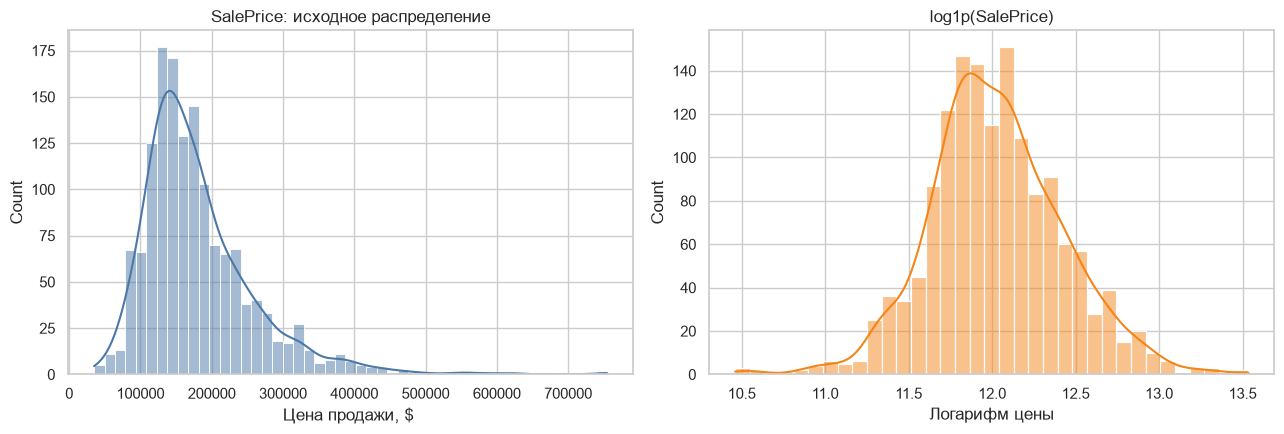

In [3]:
target_summary = train["SalePrice"].describe().to_frame("SalePrice")
target_summary.loc["skew"] = train["SalePrice"].skew()
target_summary.loc["log1p skew"] = np.log1p(train["SalePrice"]).skew()
display(target_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(train["SalePrice"], kde=True, ax=axes[0], color="#4C78A8")
axes[0].set_title("SalePrice: исходное распределение")
axes[0].set_xlabel("Цена продажи, $ ")
sns.histplot(np.log1p(train["SalePrice"]), kde=True, ax=axes[1], color="#F58518")
axes[1].set_title("log1p(SalePrice)")
axes[1].set_xlabel("Логарифм цены")
plt.tight_layout()
plt.show()

Средняя цена ($180,921) выше медианы ($163,000), а асимметрия равна 1.88. Правый хвост создают дорогие дома. После `log1p` асимметрия снижается до 0.12; логарифм цели соответствует метрике Kaggle и будет полезен на этапе моделирования.

## 3. Пропущенные значения

,Пропусков,"Доля, %"
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageQual,81,5.5
GarageFinish,81,5.5
GarageType,81,5.5


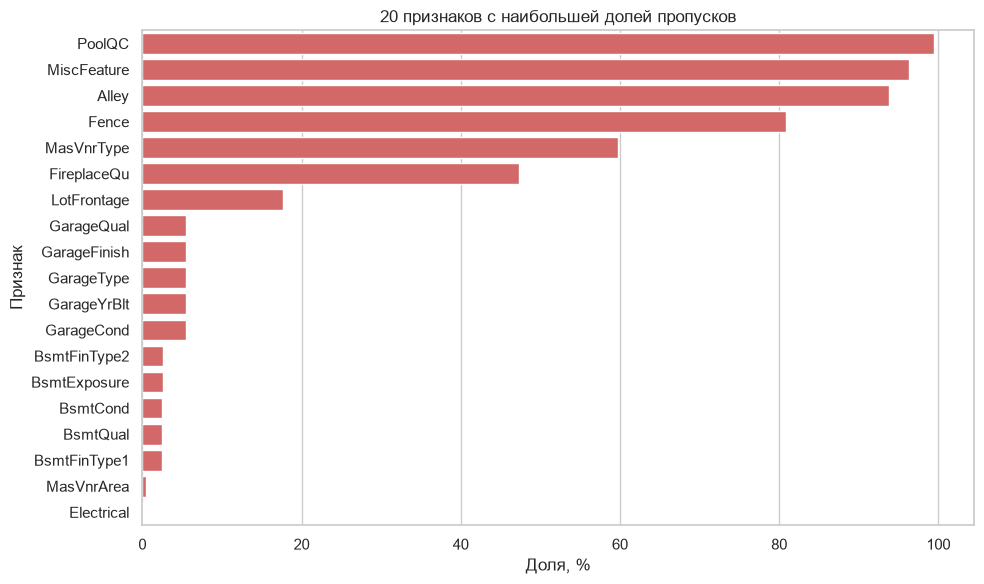

In [4]:
missing = train.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_table = pd.DataFrame(
    {"Пропусков": missing, "Доля, %": (missing / len(train) * 100).round(1)}
)
display(missing_table.head(20))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=missing_table.head(20).reset_index(),
    x="Доля, %",
    y="index",
    color="#E45756",
)
plt.title("20 признаков с наибольшей долей пропусков")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

Большая доля `NaN` не всегда означает плохое качество данных. В описании набора для `PoolQC`, `Alley`, `Fence`, `FireplaceQu` и похожих полей отсутствие значения часто означает, что соответствующего объекта у дома нет. На этапе препроцессинга такие пропуски следует отделить от действительно неизвестных значений.

## 4. Числовые признаки и связь с ценой

,Корреляция с SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


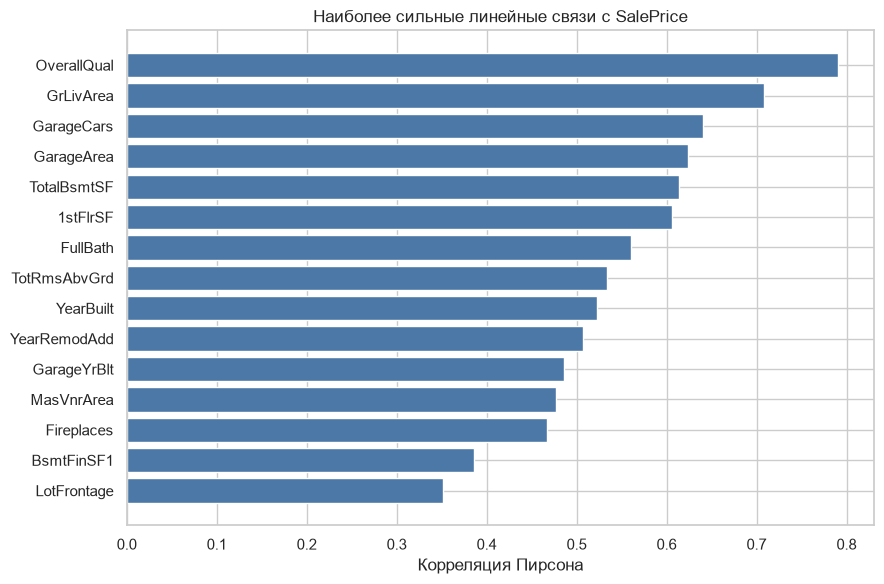

In [5]:
numeric = train.select_dtypes(include="number")
correlations = (
    numeric.corr()["SalePrice"]
    .drop(["SalePrice", "Id"])
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
display(correlations.head(15).to_frame("Корреляция с SalePrice"))

plt.figure(figsize=(9, 6))
top_corr = correlations.head(15).sort_values()
colors = ["#E45756" if value < 0 else "#4C78A8" for value in top_corr]
plt.barh(top_corr.index, top_corr.values, color=colors)
plt.title("Наиболее сильные линейные связи с SalePrice")
plt.xlabel("Корреляция Пирсона")
plt.tight_layout()
plt.show()

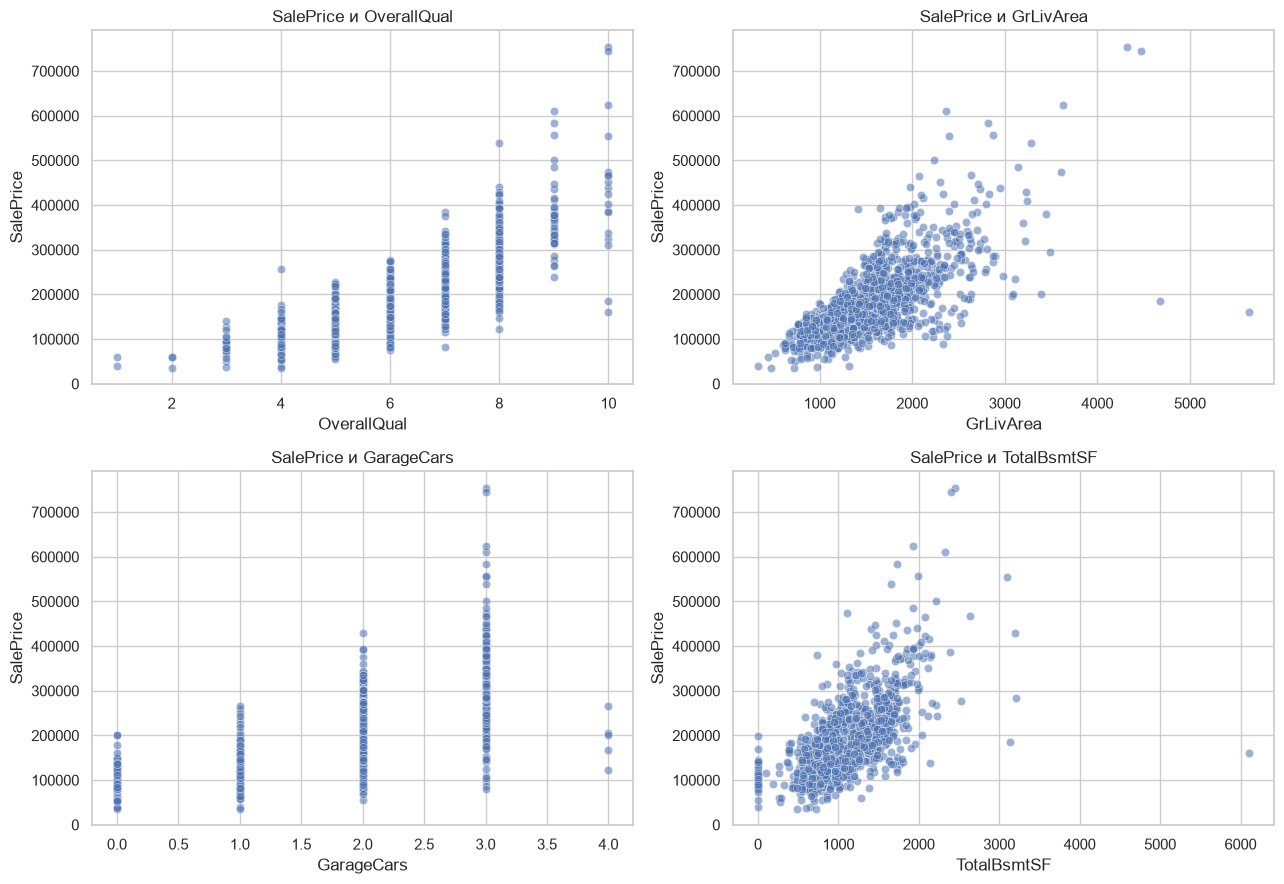

In [6]:
features = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for feature, axis in zip(features, axes.ravel()):
    sns.scatterplot(data=train, x=feature, y="SalePrice", alpha=0.55, ax=axis)
    axis.set_title(f"SalePrice и {feature}")
plt.tight_layout()
plt.show()

Самая сильная линейная связь наблюдается у `OverallQual` (0.79) и `GrLivArea` (0.71). Качество, жилая площадь, характеристики гаража и подвала дают сильный сигнал. Корреляция не показывает причинность и не выявляет нелинейные связи, поэтому это ориентир, а не правило отбора признаков.

## 5. Категориальные признаки

,count,median,mean
Neighborhood,,,
NridgHt,77,315000.0,316270.623377
NoRidge,41,301500.0,335295.317073
StoneBr,25,278000.0,310499.000000
Timber,38,228475.0,242247.447368
Somerst,86,225500.0,225379.837209
Veenker,11,218000.0,238772.727273
Crawfor,51,200624.0,210624.725490
ClearCr,28,200250.0,212565.428571
CollgCr,150,197200.0,197965.773333


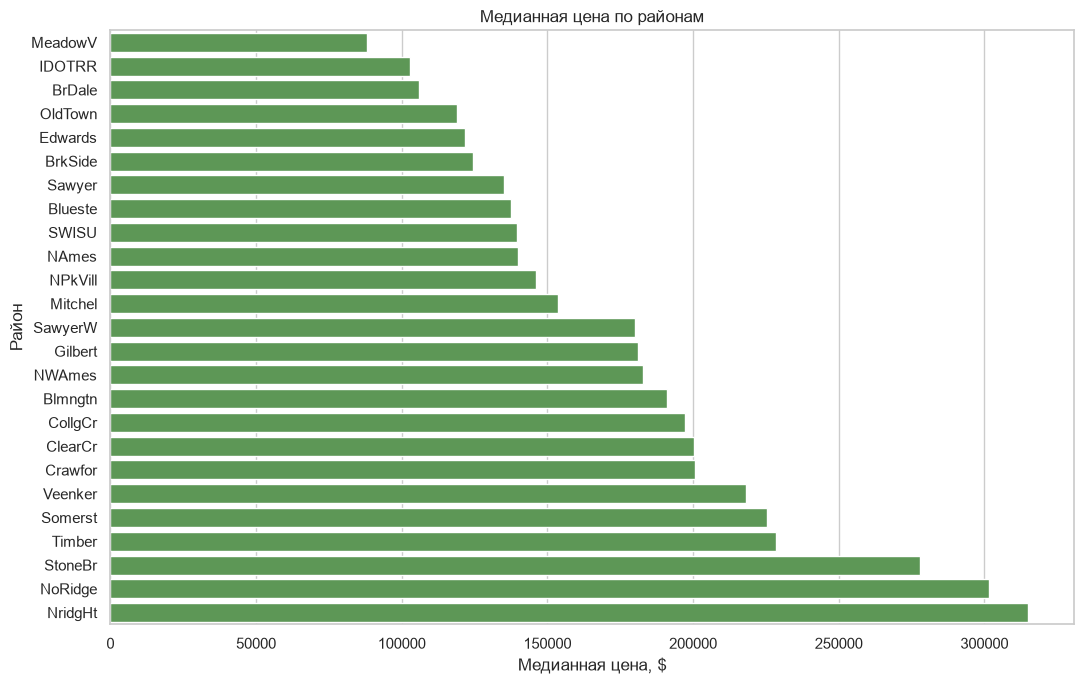

In [7]:
neighborhood = (
    train.groupby("Neighborhood", observed=True)["SalePrice"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)
display(neighborhood)

plt.figure(figsize=(11, 7))
plot_data = neighborhood.sort_values("median").reset_index()
sns.barplot(data=plot_data, x="median", y="Neighborhood", color="#54A24B")
plt.title("Медианная цена по районам")
plt.xlabel("Медианная цена, $")
plt.ylabel("Район")
plt.tight_layout()
plt.show()

Медианная цена заметно меняется между районами. Самые высокие медианы в выборке: `NridgHt` ($315,000), `NoRidge` ($301,500), `StoneBr` ($278,000). Значит, категориальные признаки содержат важную информацию и требуют корректного кодирования.

## 6. Потенциальные выбросы

,Id,Neighborhood,OverallQual,GrLivArea,SalePrice
523,524,Edwards,10,4676,184750
1298,1299,Edwards,10,5642,160000


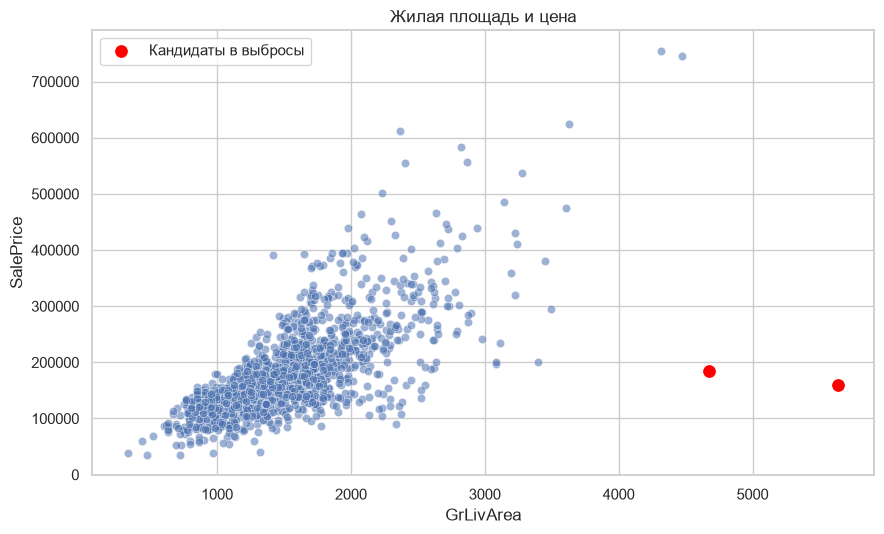

In [8]:
outlier_mask = (train["GrLivArea"] > 4000) & (train["SalePrice"] < 300_000)
candidates = train.loc[
    outlier_mask,
    ["Id", "Neighborhood", "OverallQual", "GrLivArea", "SalePrice"],
]
display(candidates)

plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", alpha=0.55)
sns.scatterplot(
    data=train.loc[outlier_mask],
    x="GrLivArea",
    y="SalePrice",
    color="red",
    s=100,
    label="Кандидаты в выбросы",
)
plt.title("Жилая площадь и цена")
plt.tight_layout()
plt.show()

По сочетанию большой жилой площади и относительно низкой цены найдено 2 явных кандидата. Они могут заметно влиять на модель, но удалять их только по графику нельзя. На этапе моделирования нужно сравнить качество с ними и без них на одинаковой кросс-валидации.

## 7. Различия между train и test

In [9]:
categorical_columns = train.select_dtypes(exclude="number").columns
unseen_rows = []
for column in categorical_columns:
    train_values = set(train[column].dropna().astype(str))
    test_values = set(test[column].dropna().astype(str))
    unseen = sorted(test_values - train_values)
    if unseen:
        unseen_rows.append((column, len(unseen), ", ".join(unseen[:5])))

unseen_categories = pd.DataFrame(
    unseen_rows,
    columns=["Признак", "Новых категорий в test", "Примеры"],
).sort_values("Новых категорий в test", ascending=False)
display(unseen_categories)

comparison_features = ["OverallQual", "GrLivArea", "YearBuilt", "TotalBsmtSF"]
comparison = pd.DataFrame(
    {
        "train median": train[comparison_features].median(),
        "test median": test[comparison_features].median(),
        "train missing, %": train[comparison_features].isna().mean().mul(100).round(2),
        "test missing, %": test[comparison_features].isna().mean().mul(100).round(2),
    }
)
display(comparison)

,Признак,Новых категорий в test,Примеры


,train median,test median,"train missing, %","test missing, %"
OverallQual,6.0,6.0,0.0,0.00
GrLivArea,1464.0,1432.0,0.0,0.00
YearBuilt,1973.0,1973.0,0.0,0.00
TotalBsmtSF,991.5,988.0,0.0,0.07


В test есть новые категории в 0 столбцах. Поэтому будущий кодировщик должен поддерживать неизвестные значения, иначе предсказание на test завершится ошибкой. По медианам ключевых числовых признаков выборки близки, но это не заменяет проверку сдвига распределений после построения базового пайплайна.

## 8. Итоговые выводы

## Данные

- Обучающая выборка: **1460 строк и 81 столбец**.
- Тестовая выборка: **1459 строк и 80 столбцов**.
- В train: **38 числовых** столбцов, включая `Id` и `SalePrice`, и **43 категориальных**.
- Полных дубликатов строк: **0**.

## Целевая переменная

- Средняя цена: **$180,921**, медиана: **$163,000**.
- Диапазон: **$34,900–$755,000**.
- Распределение имеет правый хвост: коэффициент асимметрии **1.88**.
- После `log1p` асимметрия снижается до **0.12**. Поэтому на этапе моделирования логарифмирование цели стоит проверить как основной вариант.

## Признаки и пропуски

- Пропуски есть в **19** столбцах train.
- Самые большие доли пропусков: `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%), `Fence` (80.8%), `MasVnrType` (59.7%).
- Для таких признаков, как бассейн, аллея, забор или камин, `NaN` часто означает отсутствие объекта, а не случайно потерянное значение. Это нужно учитывать при препроцессинге.
- Сильнее всего с ценой линейно связаны: `OverallQual` (0.79), `GrLivArea` (0.71), `GarageCars` (0.64), `GarageArea` (0.62), `TotalBsmtSF` (0.61), `1stFlrSF` (0.61).
- Районы заметно различаются по медианной цене, поэтому `Neighborhood` нельзя исключать только из-за категориального типа.

## Риски для следующего этапа

- Найдено **2** очевидных кандидата в выбросы: очень большая жилая площадь (`GrLivArea > 4000`) при цене ниже $300,000. Удалять их автоматически пока не следует; решение нужно проверить на кросс-валидации.
- В test встречаются неизвестные для train категории в **0** категориальных столбцах. Кодировщик должен уметь обрабатывать новые категории.
- `Id` — идентификатор, а не содержательный признак; его следует сохранить для submission, но исключить из обучения.

## Что переносим в препроцессинг

1. Разделить числовые и категориальные признаки.
2. Явно кодировать смысловые пропуски как `None`/`NoFeature`, остальные заполнять статистиками, рассчитанными только на train-fold.
3. Использовать кодирование категорий с поддержкой неизвестных значений.
4. Проверить `log1p(SalePrice)` и влияние двух кандидатов в выбросы через кросс-валидацию.
5. Не принимать окончательных решений по признакам только на основании корреляции.